# 02. Data Patterns, Correlations & Target Behaviour

**Goal:** Validate physical plausibility, analyse inter-feature relationships, seasonal dynamics,  
nutrient ratios, and the CCME target distribution. Export final cleaned dataset.

## 1. Setup & Load

In [1]:
import os, warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

DATA_PATH = 'data/Dataset/Parquet/Combined Data/Combined_dataset.parquet'
OUT_DIR   = 'data/GeneratedOutput/01.EDA'
FIG_DIR   = os.path.join(OUT_DIR, 'figures')

if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('..', '..', DATA_PATH)
    OUT_DIR   = os.path.join('..', '..', OUT_DIR)
    FIG_DIR   = os.path.join('..', '..', FIG_DIR)

os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_parquet(DATA_PATH)

chemical_cols = [
    'Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)',
    'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)',
    'pH (ph units)', 'Temperature (cel)',
    'Nitrogen (mg/l)', 'Nitrate (mg/l)'
]
short_names = {
    'Ammonia (mg/l)'                   : 'Ammonia',
    'Biochemical Oxygen Demand (mg/l)' : 'BOD',
    'Dissolved Oxygen (mg/l)'          : 'DO',
    'Orthophosphate (mg/l)'            : 'Orthophosphate',
    'pH (ph units)'                    : 'pH',
    'Temperature (cel)'                : 'Temperature',
    'Nitrogen (mg/l)'                  : 'Nitrogen',
    'Nitrate (mg/l)'                   : 'Nitrate'
}
print(f'Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')

Loaded: 2,827,977 rows × 14 columns


## 2. Physical Bounds Audit (Identifying Impossible Values)

In [2]:
bounds = {
    'pH (ph units)': (3.0, 12.0, 'pH range in natural + highly polluted water'),
    'Temperature (cel)': (0.0, 45.0, 'Natural surface water temperature (°C)'),
    'Dissolved Oxygen (mg/l)': (0.0, 25.0, 'Physically achievable DO at STP'),
    'Ammonia (mg/l)': (0.0, None, 'Non-negative concentration'),
    'Biochemical Oxygen Demand (mg/l)': (0.0, None, 'Non-negative concentration'),
    'Orthophosphate (mg/l)': (0.0, None, 'Non-negative concentration'),
    'Nitrogen (mg/l)': (0.0, None, 'Non-negative concentration'),
    'Nitrate (mg/l)': (0.0, None, 'Non-negative concentration'),
}

audit_rows = []
for col, (lo, hi, reason) in bounds.items():
    mask = pd.Series(False, index=df.index)
    if lo is not None: mask |= df[col] < lo
    if hi is not None: mask |= df[col] > hi
    n = int(mask.sum())
    audit_rows.append({
        'Parameter': col, 'Min Allowed': lo, 'Max Allowed': hi,
        'Violations': n, 'Violation %': round(n / len(df) * 100, 4), 'Rule': reason
    })

audit_df = pd.DataFrame(audit_rows)
print('Physical Bounds Audit:')
display(audit_df)

union_mask = pd.Series(False, index=df.index)
for col, (lo, hi, reason) in bounds.items():
    if lo is not None: union_mask |= df[col] < lo
    if hi is not None: union_mask |= df[col] > hi
n_union = int(union_mask.sum())
pct_union = n_union / len(df) * 100
print()
print(f'Total violation rows (union): {n_union:,}  ({pct_union:.3f}% of dataset)')
print(f'Clean rows remaining:        {len(df) - n_union:,}  ({100 - pct_union:.3f}%)')


Physical Bounds Audit:


,Parameter,Min Allowed,Max Allowed,Violations,Violation %,Rule
0,pH (ph units),3.0,12.0,1581,0.0559,pH range in natural + highly polluted water
1,Temperature (cel),0.0,45.0,6850,0.2422,Natural surface water temperature (°C)
2,Dissolved Oxygen (mg/l),0.0,25.0,0,0.0000,Physically achievable DO at STP
3,Ammonia (mg/l),0.0,NaN,2,0.0001,Non-negative concentration
4,Biochemical Oxygen Demand (mg/l),0.0,NaN,2,0.0001,Non-negative concentration
5,Orthophosphate (mg/l),0.0,NaN,10,0.0004,Non-negative concentration
6,Nitrogen (mg/l),0.0,NaN,0,0.0000,Non-negative concentration
7,Nitrate (mg/l),0.0,NaN,0,0.0000,Non-negative concentration



Total violation rows (union): 8,360  (0.296% of dataset)
Clean rows remaining:        2,819,617  (99.704%)


## 3. DO vs Temperature Saturation Curve

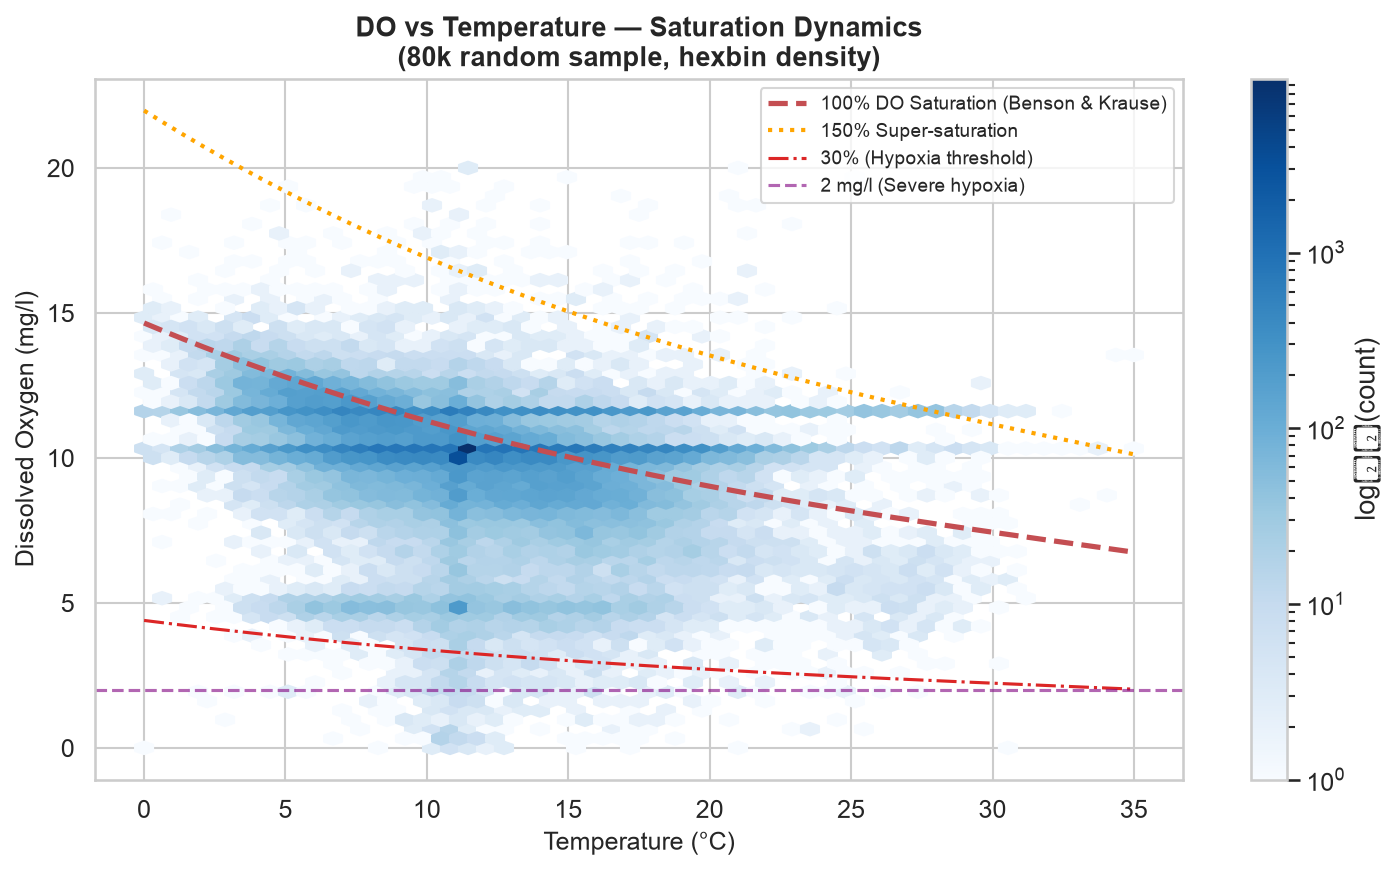

Saved → figures/07_do_temperature_saturation.png


In [3]:
sample_clean = df[
    (df['Temperature (cel)'] >= 0) & (df['Temperature (cel)'] <= 35) &
    (df['Dissolved Oxygen (mg/l)'] >= 0) & (df['Dissolved Oxygen (mg/l)'] <= 20)
].sample(80000, random_state=42)

t_curve = np.linspace(0, 35, 200)
# Benson & Krause DO saturation equation
do_sat = 14.652 - 0.41022*t_curve + 0.007991*t_curve**2 - 0.000077774*t_curve**3

fig, ax = plt.subplots(figsize=(10, 6))
hb = ax.hexbin(sample_clean['Temperature (cel)'],
               sample_clean['Dissolved Oxygen (mg/l)'],
               gridsize=55, cmap='Blues', mincnt=1, bins='log')
plt.colorbar(hb, ax=ax, label='log₁₀(count)')
ax.plot(t_curve, do_sat,        'r--',    lw=2.5, label='100% DO Saturation (Benson & Krause)')
ax.plot(t_curve, do_sat * 1.5,  color='orange', ls=':', lw=2, label='150% Super-saturation')
ax.plot(t_curve, do_sat * 0.3,  color='#dc2626', ls='-.', lw=1.5, label='30% (Hypoxia threshold)')
ax.axhline(2.0, color='purple', ls='--', lw=1.5, alpha=0.6, label='2 mg/l (Severe hypoxia)')
ax.set_xlabel('Temperature (°C)', fontsize=12)
ax.set_ylabel('Dissolved Oxygen (mg/l)', fontsize=12)
ax.set_title('DO vs Temperature — Saturation Dynamics\n(80k random sample, hexbin density)',
             fontweight='bold', fontsize=13)
ax.legend(fontsize=9, loc='upper right')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '07_do_temperature_saturation.png'))
plt.show()
print('Saved → figures/07_do_temperature_saturation.png')

## 4. IQR Outlier Analysis (Statistical, not removal — tree models are robust)

In [4]:
outlier_rows = []
for col in chemical_cols:
    s = df[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    soft_pct = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).mean() * 100
    hard_pct = ((s < q1 - 3.0*iqr) | (s > q3 + 3.0*iqr)).mean() * 100
    outlier_rows.append({'Feature': short_names[col],
                         'Q1': round(q1,3), 'Median': round(s.median(),3), 'Q3': round(q3,3),
                         'IQR': round(iqr,3),
                         'Soft (1.5×IQR) %': round(soft_pct,2),
                         'Hard (3.0×IQR) %': round(hard_pct,2)})

out_df = pd.DataFrame(outlier_rows).set_index('Feature')
print('IQR Outlier Profile (kept in dataset — tree models handle naturally):')
display(out_df)

IQR Outlier Profile (kept in dataset — tree models handle naturally):


,Q1,Median,Q3,IQR,Soft (1.5×IQR) %,Hard (3.0×IQR) %
Feature,,,,,,
Ammonia,0.030,0.055,0.317,0.287,14.31,11.49
BOD,1.600,2.700,2.830,1.230,14.60,10.44
DO,9.860,10.200,11.000,1.140,12.47,6.46
Orthophosphate,0.040,0.107,0.227,0.187,16.62,13.89
pH,7.550,7.780,8.000,0.450,4.66,0.96
Temperature,8.990,11.460,14.200,5.210,2.10,0.33
Nitrogen,0.780,4.000,6.320,5.540,7.65,2.89
Nitrate,1.173,4.500,4.940,3.767,8.88,3.99


## 5. Pearson & Spearman Correlation Heatmaps

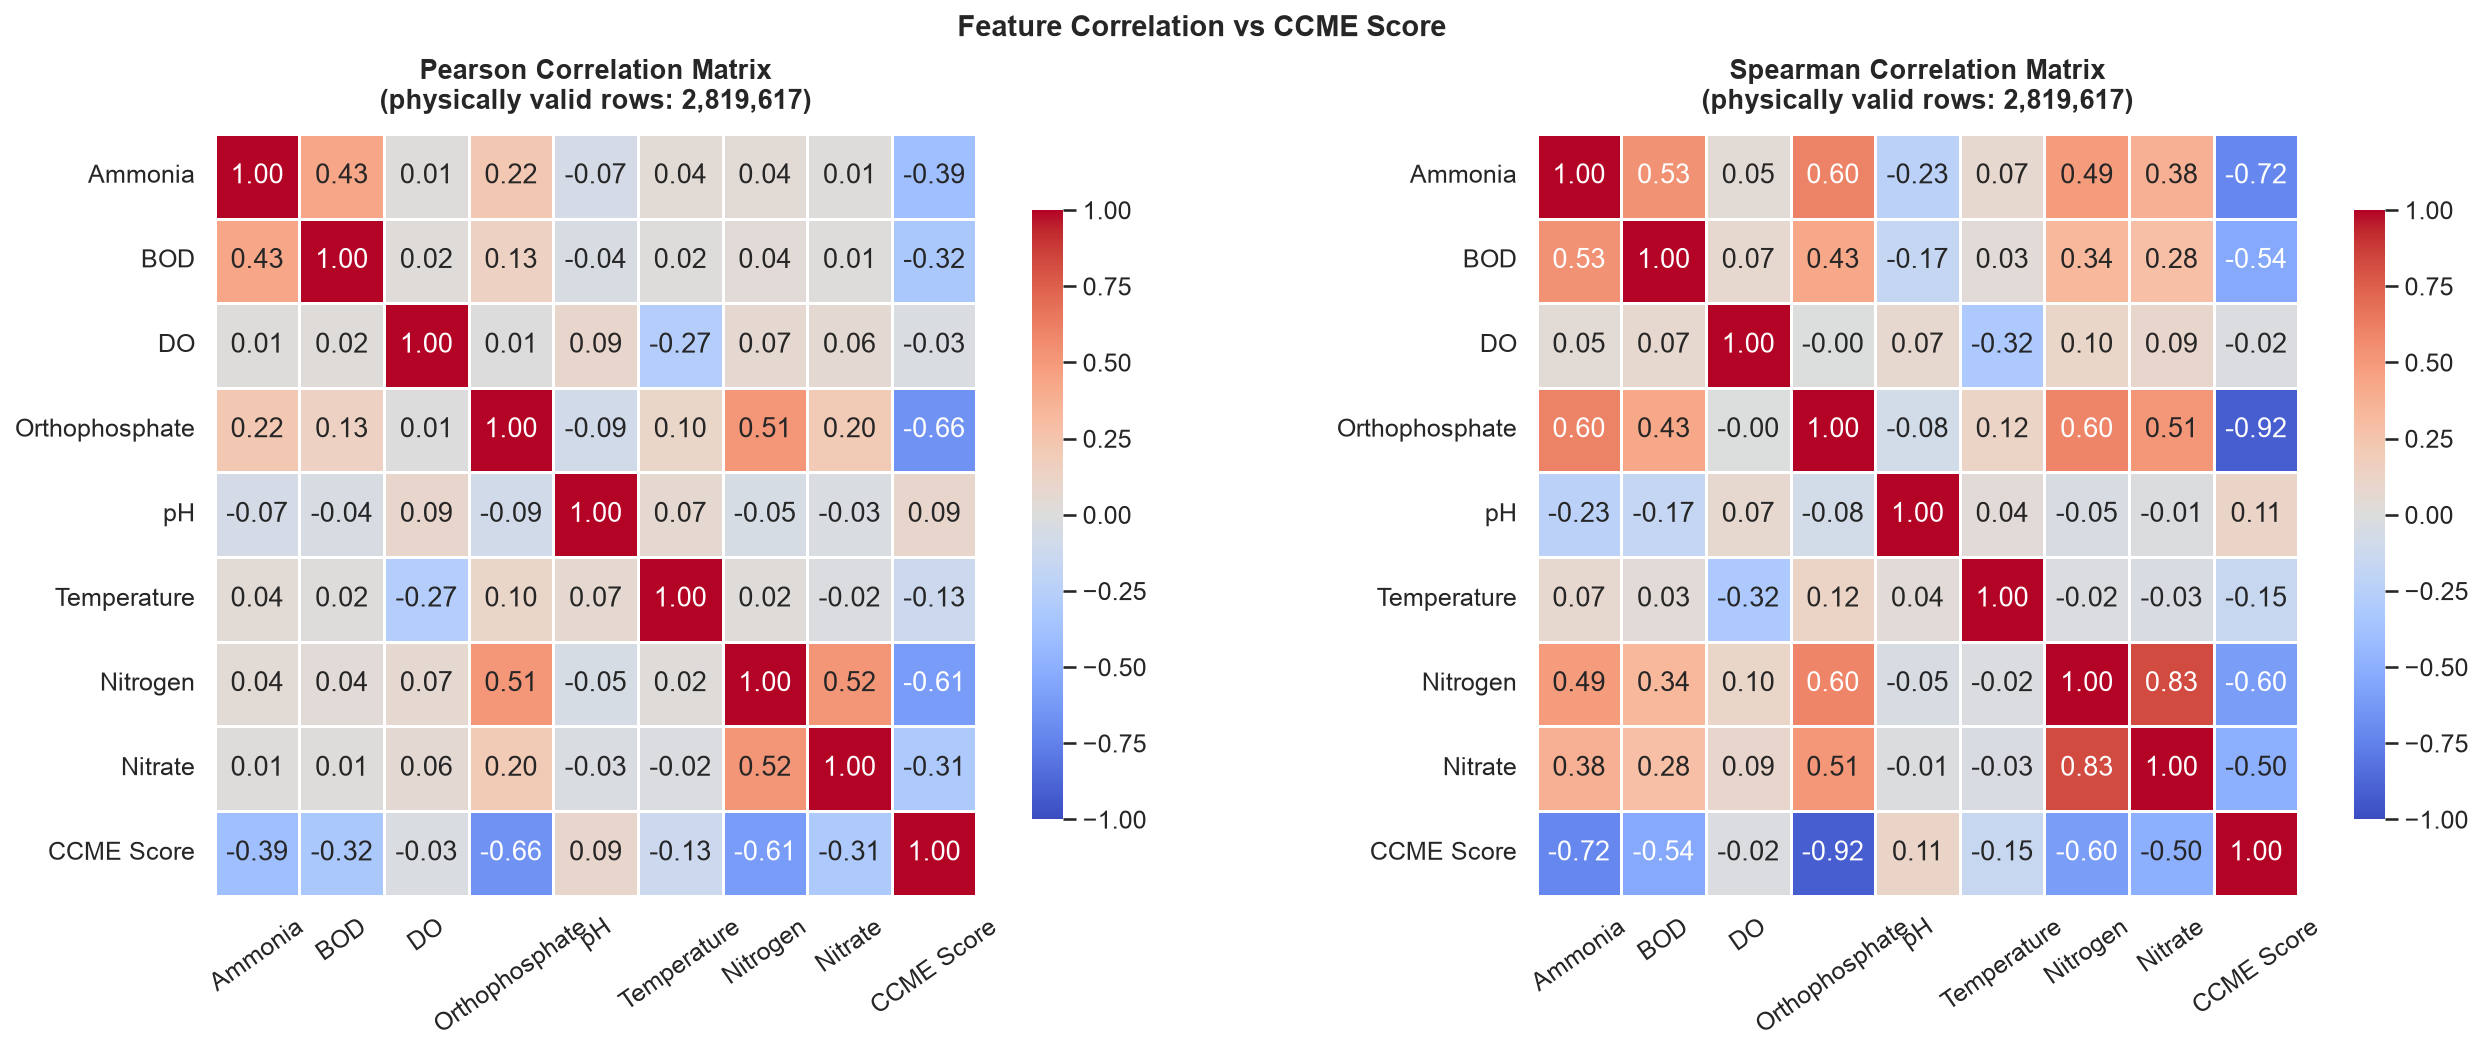

Saved → figures/08_correlation_heatmaps.png

Correlation with CCME_Values (Spearman):


,CCME Score
pH,0.110
DO,-0.022
Temperature,-0.150
Nitrate,-0.503
BOD,-0.537
Nitrogen,-0.604
Ammonia,-0.724
Orthophosphate,-0.917


In [5]:
# Use physically valid subset for correlation
df_valid = df[
    (df['pH (ph units)'] >= 3)         & (df['pH (ph units)'] <= 12) &
    (df['Temperature (cel)'] >= 0)     & (df['Temperature (cel)'] <= 45) &
    (df['Dissolved Oxygen (mg/l)'] >= 0) & (df['Dissolved Oxygen (mg/l)'] <= 25) &
    (df['Ammonia (mg/l)'] >= 0) &
    (df['Biochemical Oxygen Demand (mg/l)'] >= 0) &
    (df['Orthophosphate (mg/l)'] >= 0)
].copy()

analysis_cols = chemical_cols + ['CCME_Values']
short_analysis = {**short_names, 'CCME_Values': 'CCME Score'}
df_corr = df_valid[analysis_cols].rename(columns=short_analysis)

pearson  = df_corr.corr(method='pearson')
spearman = df_corr.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
mask = np.zeros_like(pearson, dtype=bool)

for ax, corr, title in zip(axes, [pearson, spearman], ['Pearson', 'Spearman']):
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
                vmin=-1, vmax=1, square=True, linewidths=0.5,
                cbar_kws={'shrink': 0.8}, ax=ax)
    ax.set_title(f'{title} Correlation Matrix\n(physically valid rows: {len(df_valid):,})',
                 fontweight='bold', pad=12)
    ax.tick_params(axis='x', rotation=35)
    ax.tick_params(axis='y', rotation=0)

plt.suptitle('Feature Correlation vs CCME Score', fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '08_correlation_heatmaps.png'))
plt.show()
print('Saved → figures/08_correlation_heatmaps.png')

print('\nCorrelation with CCME_Values (Spearman):')
display(spearman['CCME Score'].drop('CCME Score').sort_values(ascending=False).round(3).to_frame())

## 6. Nitrogen : Phosphate Ratio (Redfield Benchmark)

Rows used : 2,818,877
Median N:P: 26.09  (Redfield benchmark = 16:1)


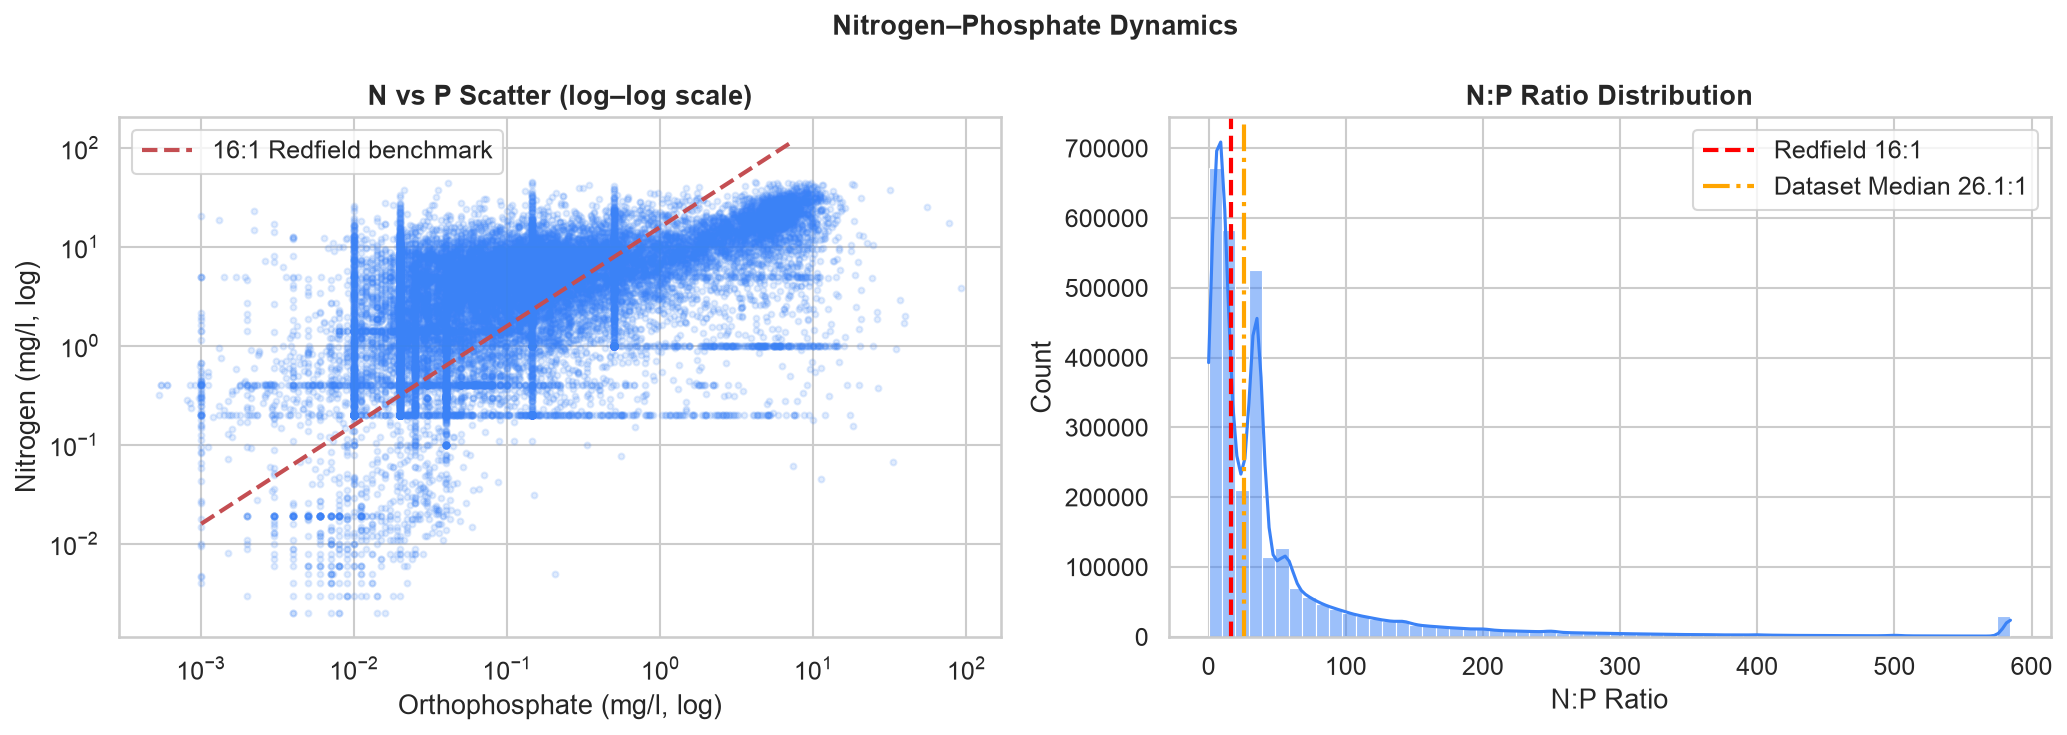

Saved → figures/09_np_ratio.png


In [6]:
np_df = df_valid[
    (df_valid['Nitrogen (mg/l)'] > 0) & (df_valid['Orthophosphate (mg/l)'] > 0)
].copy()
np_df['NP_Ratio'] = np_df['Nitrogen (mg/l)'] / np_df['Orthophosphate (mg/l)']

print(f'Rows used : {len(np_df):,}')
print(f'Median N:P: {np_df["NP_Ratio"].median():.2f}  (Redfield benchmark = 16:1)')

sample_np = np_df.sample(30000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter
p_vals = np.linspace(0.001, sample_np['Orthophosphate (mg/l)'].quantile(0.98), 200)
axes[0].scatter(sample_np['Orthophosphate (mg/l)'], sample_np['Nitrogen (mg/l)'],
                alpha=0.15, s=8, c='#3b82f6')
axes[0].plot(p_vals, p_vals * 16, 'r--', lw=2, label='16:1 Redfield benchmark')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Orthophosphate (mg/l, log)')
axes[0].set_ylabel('Nitrogen (mg/l, log)')
axes[0].set_title('N vs P Scatter (log–log scale)', fontweight='bold')
axes[0].legend()

# N:P ratio histogram
ratio_clip = np_df['NP_Ratio'].clip(upper=np_df['NP_Ratio'].quantile(0.99))
sns.histplot(ratio_clip, bins=60, kde=True, ax=axes[1], color='#3b82f6')
axes[1].axvline(16, color='red', ls='--', lw=2, label='Redfield 16:1')
axes[1].axvline(ratio_clip.median(), color='orange', ls='-.', lw=2,
                label=f'Dataset Median {ratio_clip.median():.1f}:1')
axes[1].set_xlabel('N:P Ratio')
axes[1].set_ylabel('Count')
axes[1].set_title('N:P Ratio Distribution', fontweight='bold')
axes[1].legend()

plt.suptitle('Nitrogen–Phosphate Dynamics', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '09_np_ratio.png'))
plt.show()
print('Saved → figures/09_np_ratio.png')

## 7. Seasonal (Monthly) Patterns

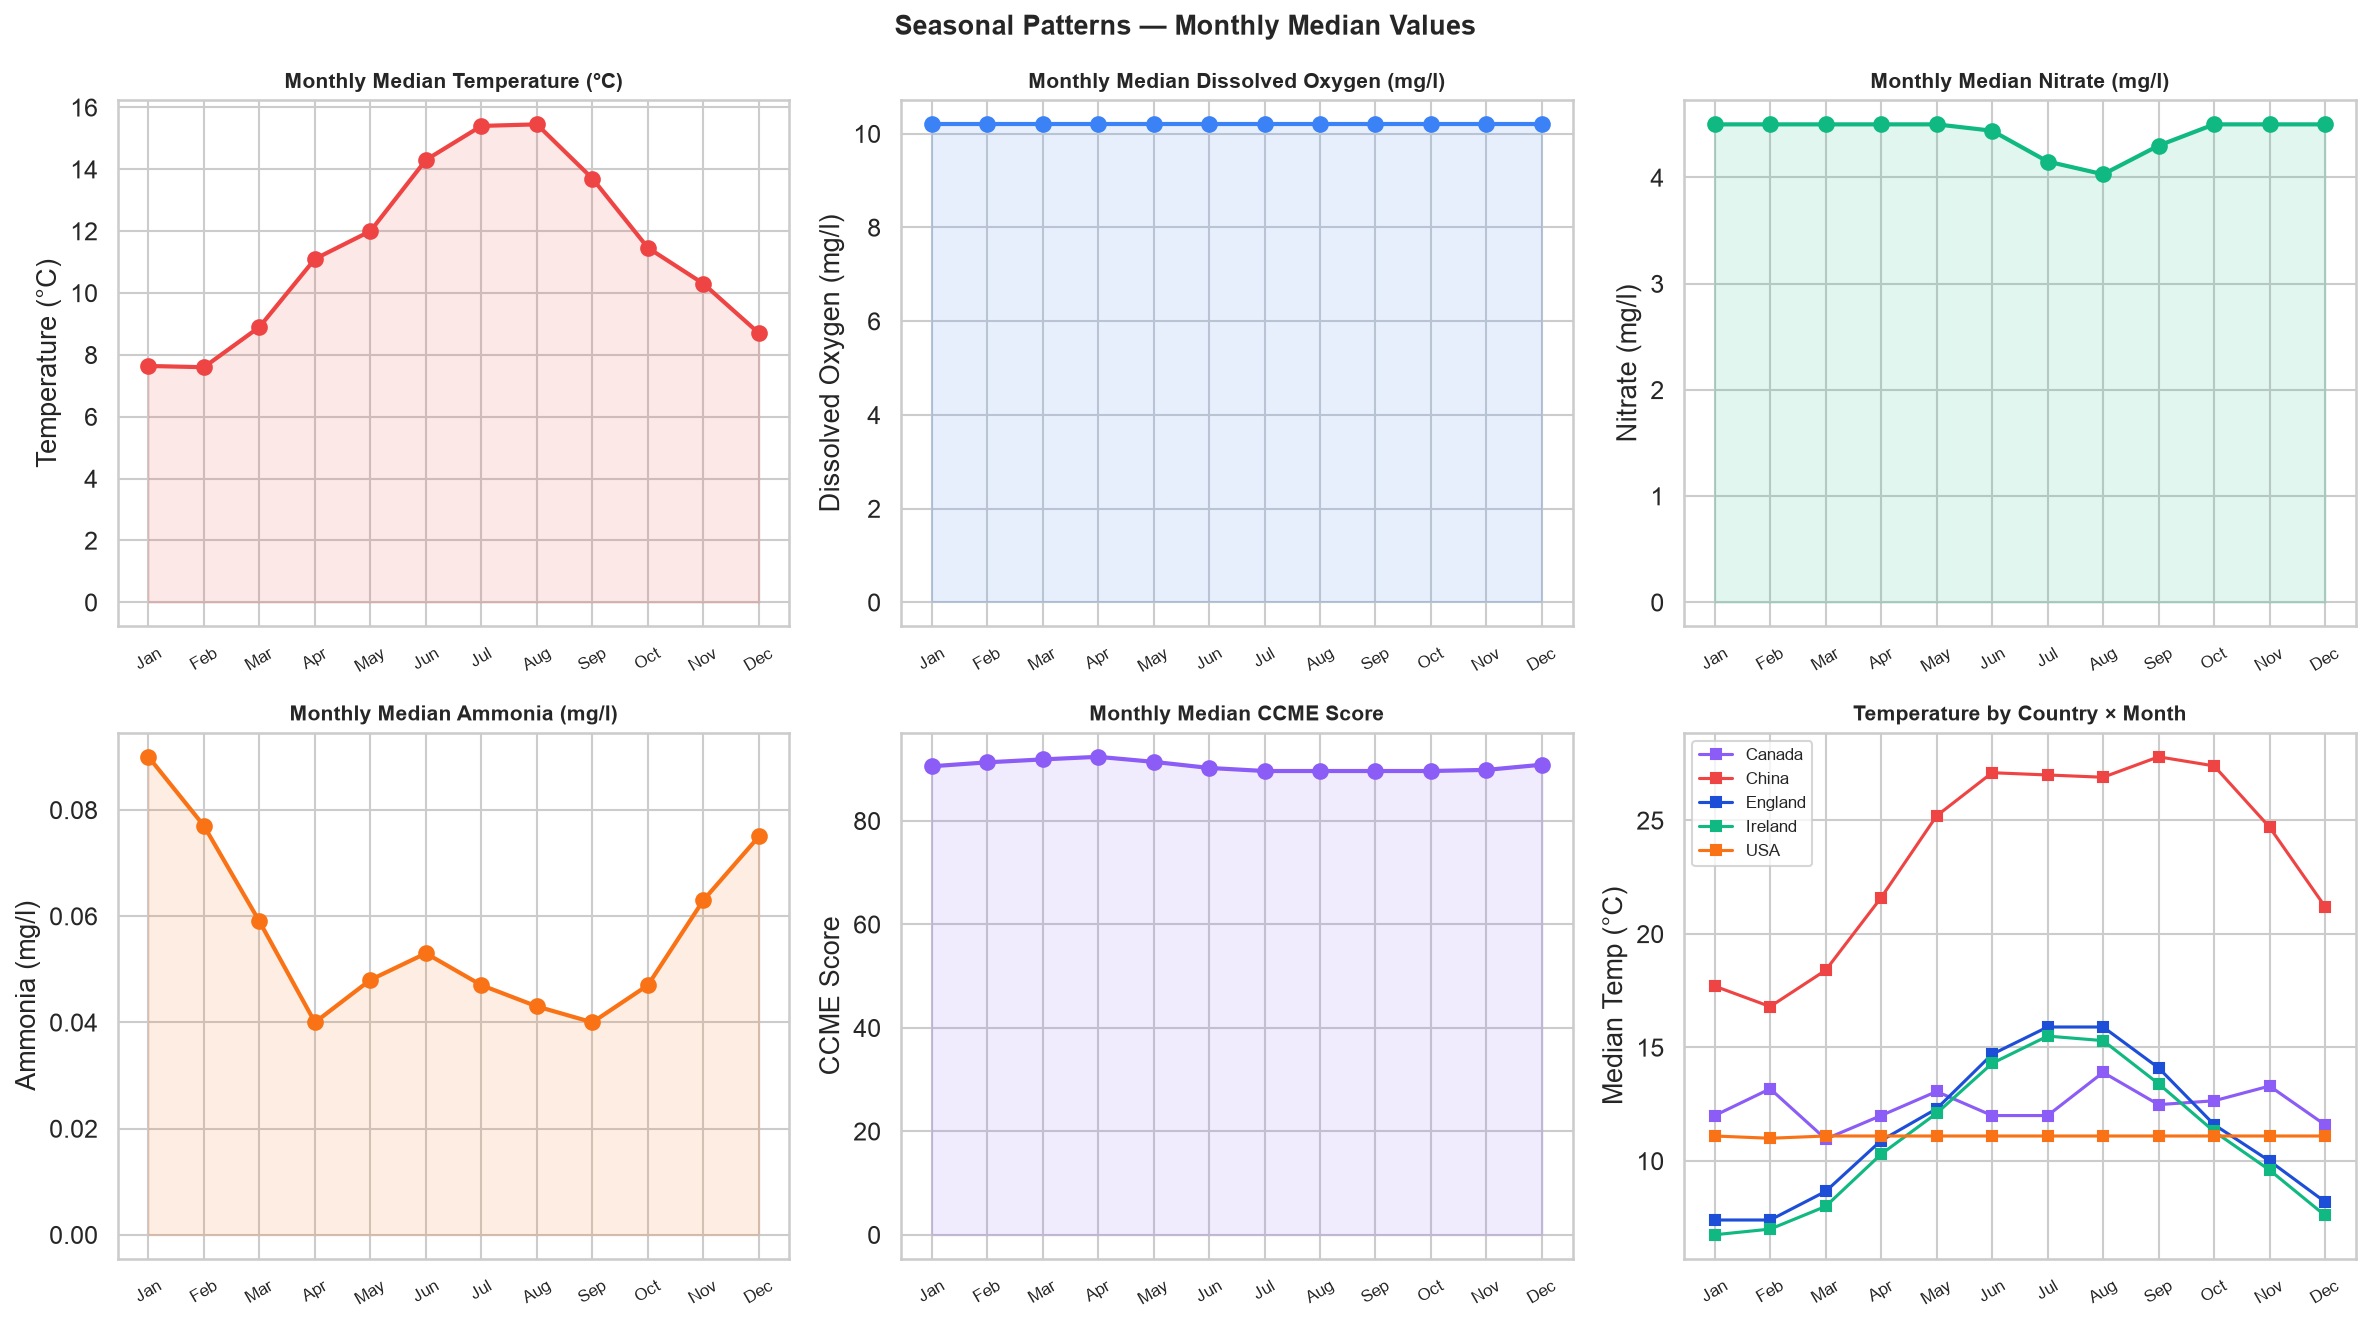

Saved → figures/10_seasonal_patterns.png


In [7]:
df['Month'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce').dt.month
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

monthly = df.groupby('Month')[[
    'Temperature (cel)', 'Dissolved Oxygen (mg/l)',
    'Nitrate (mg/l)', 'Ammonia (mg/l)', 'CCME_Values'
]].median()
monthly.index = month_names

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

configs = [
    ('Temperature (cel)',         'Temperature (°C)',     '#ef4444'),
    ('Dissolved Oxygen (mg/l)',   'Dissolved Oxygen (mg/l)', '#3b82f6'),
    ('Nitrate (mg/l)',            'Nitrate (mg/l)',        '#10b981'),
    ('Ammonia (mg/l)',            'Ammonia (mg/l)',        '#f97316'),
    ('CCME_Values',               'CCME Score',           '#8b5cf6'),
]

for i, (col, label, color) in enumerate(configs):
    axes[i].plot(monthly.index, monthly[col], marker='o', color=color, lw=2, ms=7)
    axes[i].fill_between(range(12), monthly[col].values, alpha=0.12, color=color)
    axes[i].set_xticks(range(12))
    axes[i].set_xticklabels(month_names, rotation=30, fontsize=8)
    axes[i].set_title(f'Monthly Median {label}', fontweight='bold', fontsize=10)
    axes[i].set_ylabel(label)

# Country × month for temperature (last subplot)
country_month = df.groupby(['Country','Month'])['Temperature (cel)'].median().unstack()
country_month.columns = month_names
country_colors = {'England':'#1d4ed8','USA':'#f97316','Ireland':'#10b981','China':'#ef4444','Canada':'#8b5cf6'}
for country in country_month.index:
    axes[5].plot(month_names, country_month.loc[country], marker='s', ms=5, lw=1.5,
                 label=country, color=country_colors.get(country,'gray'))
axes[5].set_title('Temperature by Country × Month', fontweight='bold', fontsize=10)
axes[5].set_ylabel('Median Temp (°C)')
axes[5].set_xticks(range(12))
axes[5].set_xticklabels(month_names, rotation=30, fontsize=8)
axes[5].legend(fontsize=8)

plt.suptitle('Seasonal Patterns — Monthly Median Values', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '10_seasonal_patterns.png'))
plt.show()
print('Saved → figures/10_seasonal_patterns.png')

## 8. Target Variable — CCME Score & WQI Class Distribution

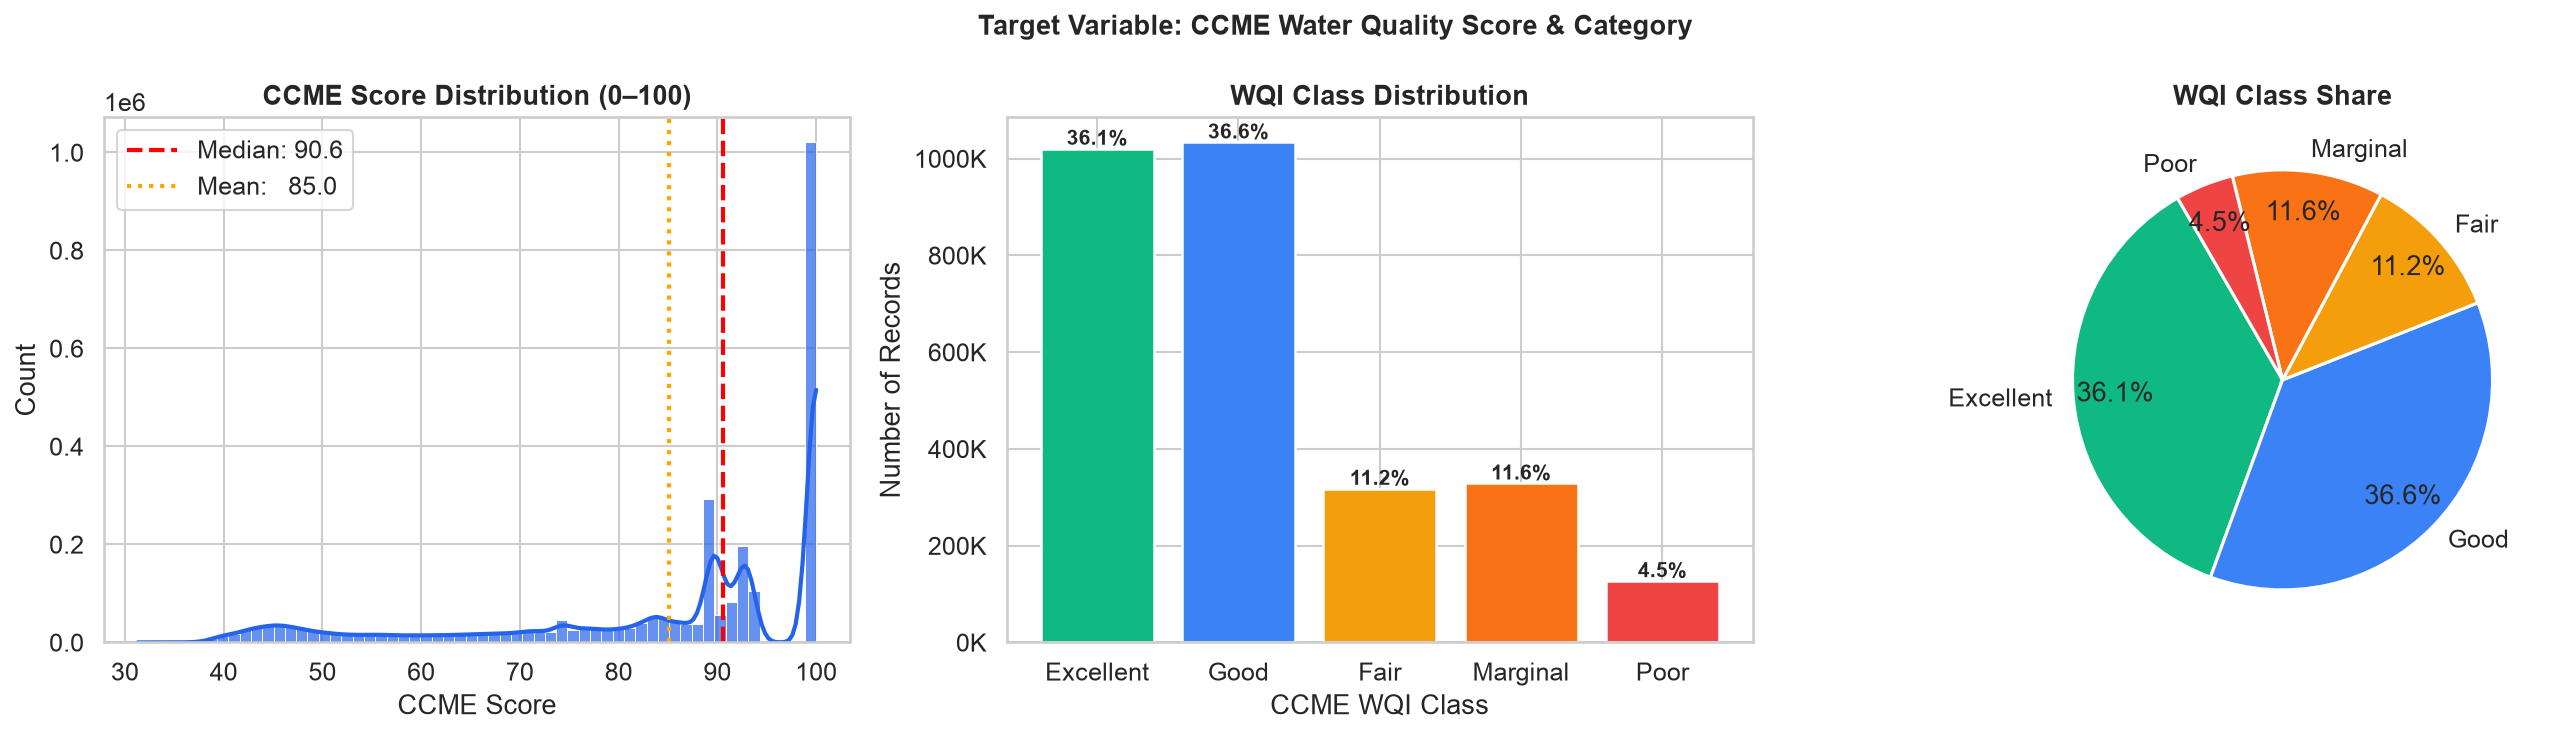

Saved → figures/11_target_distribution.png


In [8]:
wqi_order  = ['Excellent', 'Good', 'Fair', 'Marginal', 'Poor']
wqi_colors = ['#10b981', '#3b82f6', '#f59e0b', '#f97316', '#ef4444']
wqi_counts = df['CCME_WQI'].value_counts().reindex(wqi_order)
wqi_pcts   = (wqi_counts / len(df) * 100).round(1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram
sns.histplot(df['CCME_Values'], bins=60, kde=True, ax=axes[0],
             color='#2563eb', alpha=0.7, line_kws={'lw':2})
axes[0].axvline(df['CCME_Values'].median(), color='red',    ls='--', lw=2,
                label=f'Median: {df["CCME_Values"].median():.1f}')
axes[0].axvline(df['CCME_Values'].mean(),   color='orange', ls=':',  lw=2,
                label=f'Mean:   {df["CCME_Values"].mean():.1f}')
axes[0].set_title('CCME Score Distribution (0–100)', fontweight='bold')
axes[0].set_xlabel('CCME Score')
axes[0].set_ylabel('Count')
axes[0].legend()

# WQI bar
bars = axes[1].bar(wqi_order, wqi_counts.values, color=wqi_colors, edgecolor='white', linewidth=1.2)
for bar, pct in zip(bars, wqi_pcts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 8000,
                 f'{pct}%', ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('WQI Class Distribution', fontweight='bold')
axes[1].set_xlabel('CCME WQI Class')
axes[1].set_ylabel('Number of Records')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{int(x/1e3)}K'))

# Pie
axes[2].pie(wqi_counts.values, labels=wqi_order, colors=wqi_colors,
            autopct='%1.1f%%', startangle=120, pctdistance=0.80,
            wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[2].set_title('WQI Class Share', fontweight='bold')

plt.suptitle('Target Variable: CCME Water Quality Score & Category', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '11_target_distribution.png'))
plt.show()
print('Saved → figures/11_target_distribution.png')

## 9. CCME Score by Country & Waterbody Type

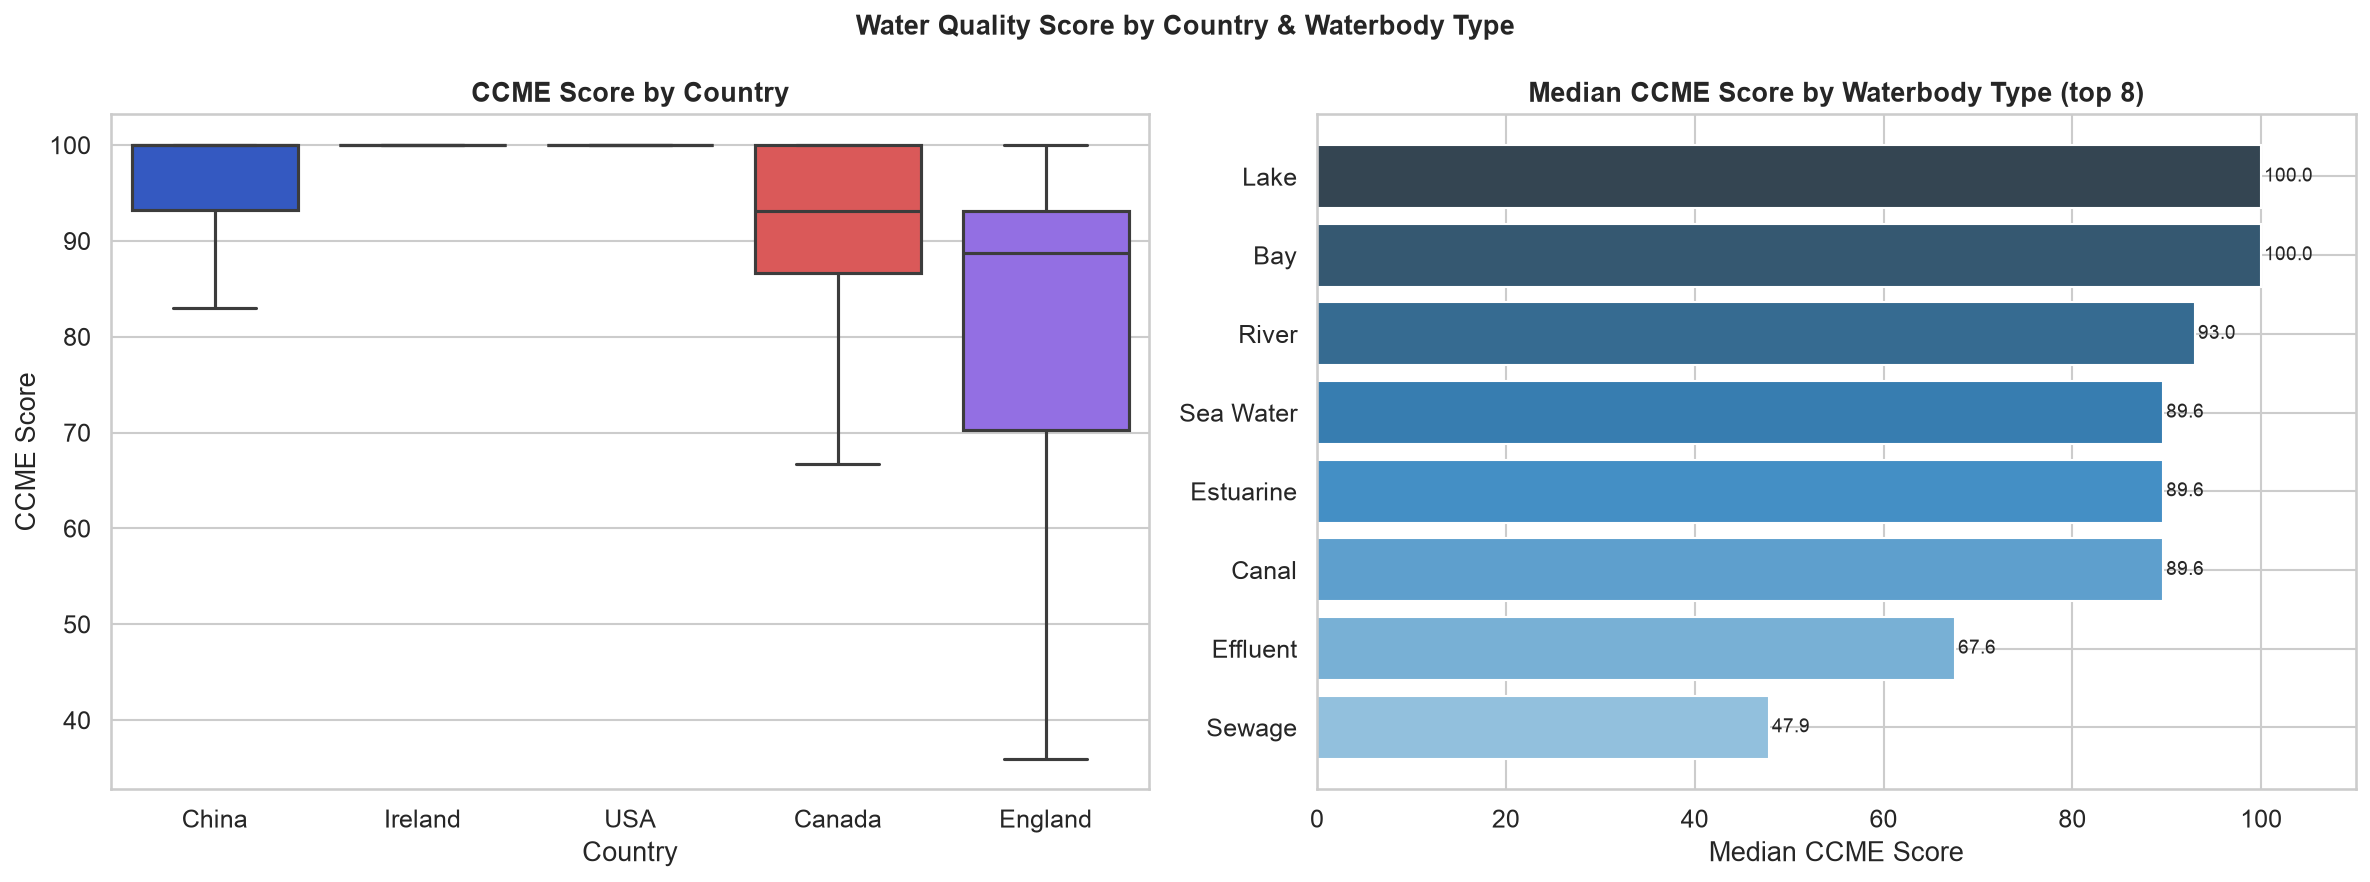

Saved → figures/12_ccme_by_country_waterbody.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Box by country using seaborn (supports order)
country_order = df.groupby("Country")["CCME_Values"].median().sort_values(ascending=False).index.tolist()
country_palette = dict(zip(country_order, ["#1d4ed8","#f97316","#10b981","#ef4444","#8b5cf6"]))
sns.boxplot(data=df, x="Country", y="CCME_Values", order=country_order,
            palette=country_palette, showfliers=False,
            linewidth=1.5, ax=axes[0])
axes[0].set_title("CCME Score by Country", fontweight="bold")
axes[0].set_xlabel("Country"); axes[0].set_ylabel("CCME Score")

# Median CCME by waterbody type
top_wb = df["Waterbody Type"].value_counts().head(8).index
df_wb = df[df["Waterbody Type"].isin(top_wb)]
wb_median = df_wb.groupby("Waterbody Type")["CCME_Values"].median().sort_values(ascending=True)
colors_wb = sns.color_palette("Blues_d", len(wb_median))
axes[1].barh(wb_median.index, wb_median.values, color=colors_wb, edgecolor="white")
for i, (wb, val) in enumerate(wb_median.items()):
    axes[1].text(val + 0.3, i, f"{val:.1f}", va="center", fontsize=9)
axes[1].set_title("Median CCME Score by Waterbody Type (top 8)", fontweight="bold")
axes[1].set_xlabel("Median CCME Score")
axes[1].set_xlim(0, 110)

plt.suptitle("Water Quality Score by Country & Waterbody Type", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "12_ccme_by_country_waterbody.png"))
plt.show()
print("Saved → figures/12_ccme_by_country_waterbody.png")


## 10. Pairplot — Key Features vs CCME Score

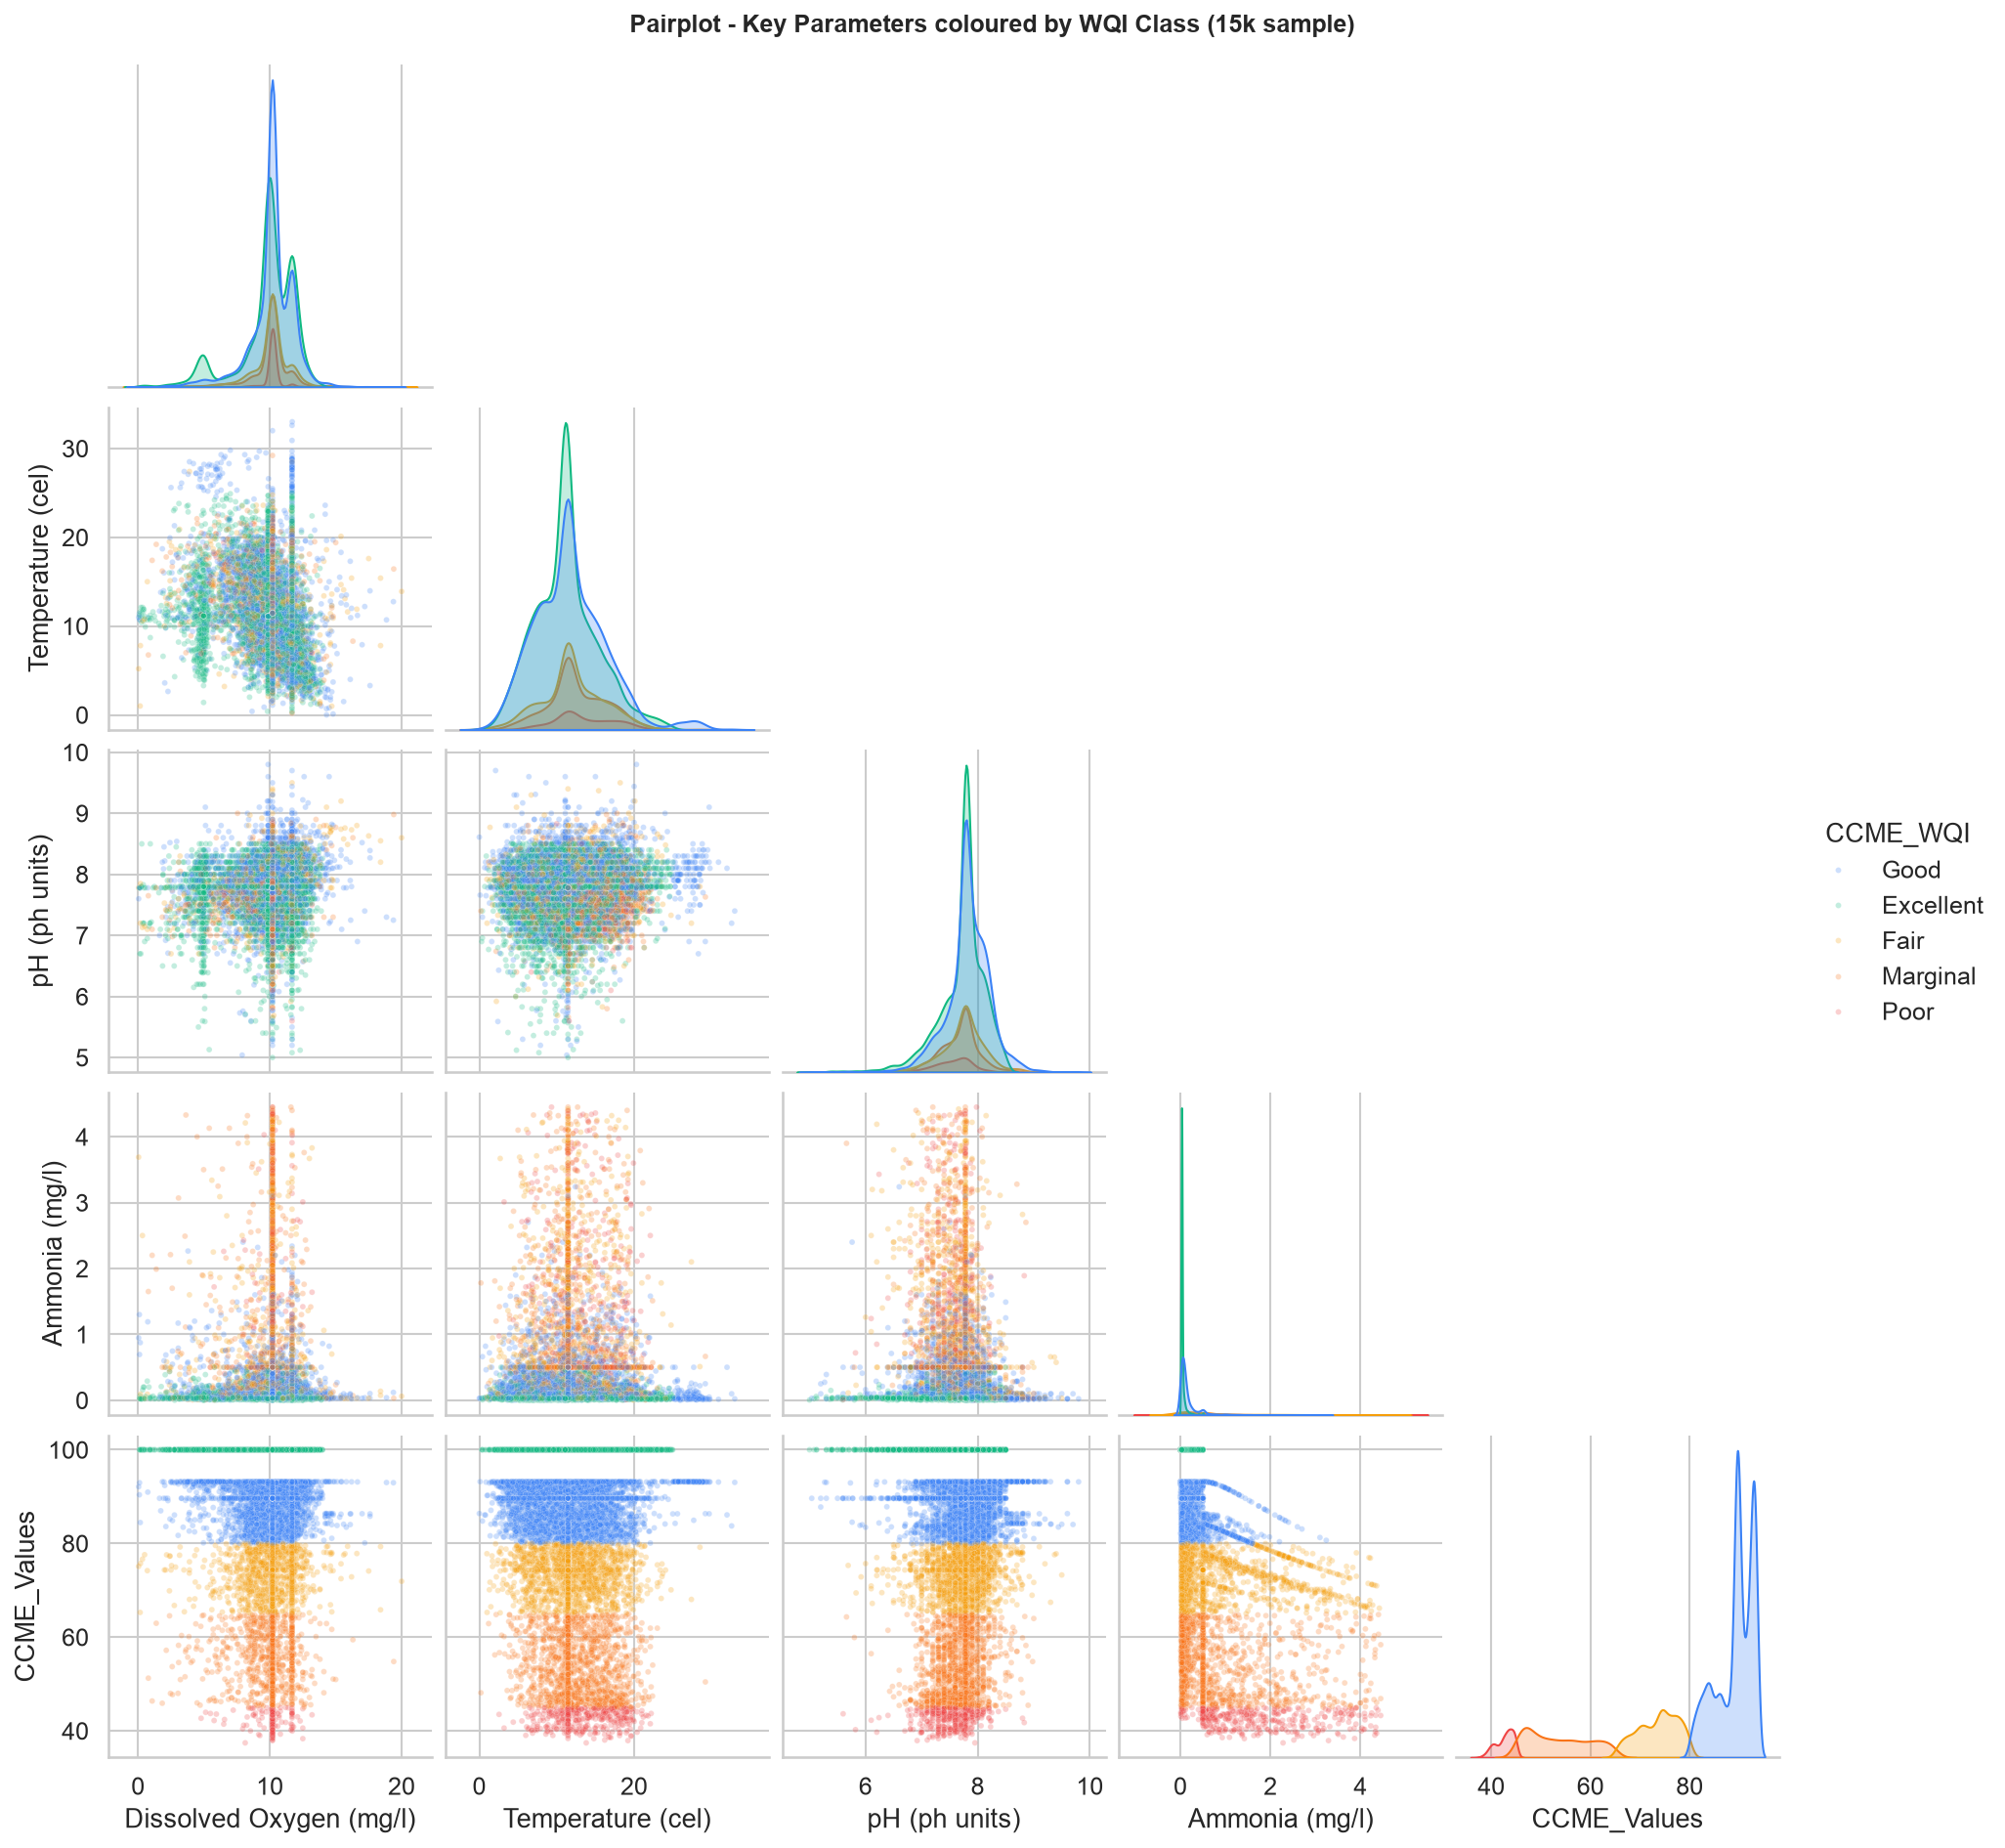

Saved: figures/13_pairplot_key_features.png


In [10]:
# Sample for speed
key_features = ["Dissolved Oxygen (mg/l)", "Temperature (cel)", "pH (ph units)",
                "Ammonia (mg/l)", "CCME_Values", "CCME_WQI"]

wqi_palette = {"Excellent":"#10b981","Good":"#3b82f6","Fair":"#f59e0b",
               "Marginal":"#f97316","Poor":"#ef4444"}

sample_pair = df[key_features].copy()
sample_pair = sample_pair[
    (sample_pair["pH (ph units)"] >= 5) & (sample_pair["pH (ph units)"] <= 10) &
    (sample_pair["Temperature (cel)"] >= 0) & (sample_pair["Temperature (cel)"] <= 35) &
    (sample_pair["Ammonia (mg/l)"] <= sample_pair["Ammonia (mg/l)"].quantile(0.95))
].sample(15000, random_state=42)

# hue must be a column NAME string inside the dataframe
g = sns.pairplot(sample_pair,
                 hue="CCME_WQI",
                 palette=wqi_palette,
                 vars=["Dissolved Oxygen (mg/l)", "Temperature (cel)",
                       "pH (ph units)", "Ammonia (mg/l)", "CCME_Values"],
                 plot_kws={"alpha": 0.25, "s": 8},
                 diag_kind="kde",
                 corner=True)
title = "Pairplot - Key Parameters coloured by WQI Class (15k sample)"
g.figure.suptitle(title, y=1.01, fontsize=12, fontweight="bold")
g.figure.savefig(os.path.join(FIG_DIR, "13_pairplot_key_features.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Saved: figures/13_pairplot_key_features.png")


## 11. Physical Validation & Export Final Cleaned Dataset

In [11]:
# Apply physical bounds filter to remove physically impossible rows
valid_mask = (
    (df['pH (ph units)'] >= 3.0) & (df['pH (ph units)'] <= 12.0) &
    (df['Temperature (cel)'] >= 0.0) & (df['Temperature (cel)'] <= 45.0) &
    (df['Dissolved Oxygen (mg/l)'] >= 0.0) & (df['Dissolved Oxygen (mg/l)'] <= 25.0) &
    (df['Ammonia (mg/l)'] >= 0.0) &
    (df['Biochemical Oxygen Demand (mg/l)'] >= 0.0) &
    (df['Orthophosphate (mg/l)'] >= 0.0) &
    (df['Nitrogen (mg/l)'] >= 0.0) &
    (df['Nitrate (mg/l)'] >= 0.0)
)

cleaned_df = df[valid_mask][[
    'Country', 'Area', 'Waterbody Type', 'Date',
    'Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)',
    'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)',
    'pH (ph units)', 'Temperature (cel)',
    'Nitrogen (mg/l)', 'Nitrate (mg/l)',
    'CCME_Values', 'CCME_WQI'
]].copy()

removed = len(df) - len(cleaned_df)
print(f'Raw rows    : {len(df):,}')
print(f'Clean rows  : {len(cleaned_df):,}')
print(f'Removed     : {removed:,}  ({removed/len(df)*100:.3f}%)  — physically impossible values only')
print(f'Null values : {cleaned_df.isnull().sum().sum()}  (should be 0)')
print(f'Countries   : {cleaned_df["Country"].unique().tolist()}')

final_path = os.path.join(OUT_DIR, 'final_eda_cleaned_dataset.parquet')
cleaned_df.to_parquet(final_path, index=False, compression='snappy')
print(f'\nExported → {final_path}')


Raw rows    : 2,827,977
Clean rows  : 2,819,617
Removed     : 8,360  (0.296%)  — physically impossible values only
Null values : 0  (should be 0)
Countries   : ['Canada', 'England', 'China', 'USA', 'Ireland']



Exported → ../../data/GeneratedOutput/01.EDA/final_eda_cleaned_dataset.parquet


## EDA Summary

| Step | Finding |
|---|
| Raw dataset | 2,827,977 rows × 14 cols, **0 nulls** |
| Physical outliers removed | **8,360 rows (0.296%)** — impossible values only |
| Final cleaned dataset | **2,819,617 rows** — all complete, physically valid |
| Key correlation (Spearman) | DO ↑ → CCME↑; Temperature ↑ → DO↓ (inverse) |
| Seasonal pattern | Temperature peaks Jul–Aug, DO inversely dips |
| Target skew | Right-skewed toward Excellent/Good (72.7% combined) |
| Figures saved | 13 publication-quality PNGs in `data/GeneratedOutput/01.EDA/figures/` |
